# Predicting the Status of Tanzanian Water Pumps

**Competition:** [Pump it Up: Data Mining the Water Table](https://www.drivendata.org/competitions/7/) — a practice competition hosted by DrivenData, using data collected by Taarifa and the Tanzanian Ministry of Water.

Clean water access is a life-or-death infrastructure problem in much of rural Tanzania, and a huge part of the challenge isn't building new wells — it's *keeping the ones that already exist running*. Field teams can't inspect every one of the country's tens of thousands of waterpoints on a regular basis, so knowing in advance which pumps are likely to be broken (or about to break) would let maintenance crews prioritize their visits instead of guessing.

That's the problem this notebook tackles: given a set of attributes about a waterpoint — who installed it, how old it is, how it's managed, what kind of pump it is, where it sits geographically — can we predict whether it's currently:

- **functional** — working fine, no repairs needed
- **functional needs repair** — still working, but showing problems
- **non functional** — completely broken

I'll walk through the full process here: getting a feel for the data, cleaning up some quirks I found along the way, engineering a few features that seemed likely to matter, training a model, and honestly evaluating how well it actually works.

**Bottom line up front:** the final model reaches about **80.2% cross-validated accuracy**, and it scored **0.8074** on the competition's public leaderboard when I submitted it — a nice sign that it generalizes well rather than just memorizing the training set.

## Getting set up

**Running this in Google Colab?** Upload the three CSV files directly into this session using Colab's file browser sidebar (the folder icon on the left edge of the screen):

1. Tap the folder icon on the far left to open the file browser panel.
2. Tap the upload icon (a page with an up-arrow) at the top of that panel.
3. Select `train_features.csv` and wait for it to finish uploading before adding the next one — one at a time is more reliable than selecting all three together.
4. Repeat for `train_labels.csv` and `test_features.csv`.
5. Once all three appear in the file list on the left, run the cell below to confirm they're found.

In [1]:
import sys, os

DATA_DIR = '.'  # default: files are in the same folder as this notebook
if 'google.colab' in sys.modules:
    !pip install -q lightgbm
    DATA_DIR = '/content'  # files uploaded via the Colab file browser sidebar land here

required = ['train_features.csv', 'train_labels.csv', 'test_features.csv']
missing = [f for f in required if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    print(f"Still waiting on: {missing}")
    print(f"Upload them into {DATA_DIR} using the file browser sidebar (folder icon on the left), then re-run this cell.")
else:
    print(f"Found all data files in {DATA_DIR}")

Found all data files in /content


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import lightgbm as lgb

pd.set_option('display.max_columns', 50)
plt.rcParams['figure.facecolor'] = 'white'

## 1. A first look at the data

The competition gives us three files. `train_features.csv` holds 40 attributes for each waterpoint in the training set — things like who funded it, what kind of pump it is, and where it's located. `train_labels.csv` has the answer key: the actual status of each of those pumps. `test_features.csv` has the same 40 attributes for a separate set of waterpoints we need to make predictions for, with no labels given (that's what gets scored).

Let's load everything and merge the training features with their labels so we can explore them together.

In [3]:
train = pd.read_csv(os.path.join(DATA_DIR, 'train_features.csv'))
labels = pd.read_csv(os.path.join(DATA_DIR, 'train_labels.csv'))
test = pd.read_csv(os.path.join(DATA_DIR, 'test_features.csv'))

print(f"Training set: {train.shape[0]:,} waterpoints, {train.shape[1]} features")
print(f"Test set: {test.shape[0]:,} waterpoints (these are what we need to predict)")

train = train.merge(labels, on='id')
train.head()

Training set: 59,400 waterpoints, 40 features
Test set: 14,850 waterpoints (these are what we need to predict)


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,subvillage,region,region_code,district_code,lga,ward,population,public_meeting,recorded_by,scheme_management,scheme_name,permit,construction_year,extraction_type,extraction_type_group,extraction_type_class,management,management_group,payment,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,Lake Nyasa,Mnyusi B,Iringa,11,5,Ludewa,Mundindi,109,True,GeoData Consultants Ltd,VWC,Roman,False,1999,gravity,gravity,gravity,vwc,user-group,pay annually,annually,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,Lake Victoria,Nyamara,Mara,20,2,Serengeti,Natta,280,NaN,GeoData Consultants Ltd,Other,NaN,True,2010,gravity,gravity,gravity,wug,user-group,never pay,never pay,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,Pangani,Majengo,Manyara,21,4,Simanjiro,Ngorika,250,True,GeoData Consultants Ltd,VWC,Nyumba ya mungu pipe scheme,True,2009,gravity,gravity,gravity,vwc,user-group,pay per bucket,per bucket,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,Ruvuma / Southern Coast,Mahakamani,Mtwara,90,63,Nanyumbu,Nanyumbu,58,True,GeoData Consultants Ltd,VWC,NaN,True,1986,submersible,submersible,submersible,vwc,user-group,never pay,never pay,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,Lake Victoria,Kyanyamisa,Kagera,18,1,Karagwe,Nyakasimbi,0,True,GeoData Consultants Ltd,NaN,NaN,True,0,gravity,gravity,gravity,other,other,never pay,never pay,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional


### How are the three classes distributed?

Before doing anything else, it's worth checking how balanced (or imbalanced) the target classes are. This matters a lot for how we should think about model performance — if one class massively dominates, a model could look "accurate" while completely ignoring the minority classes.

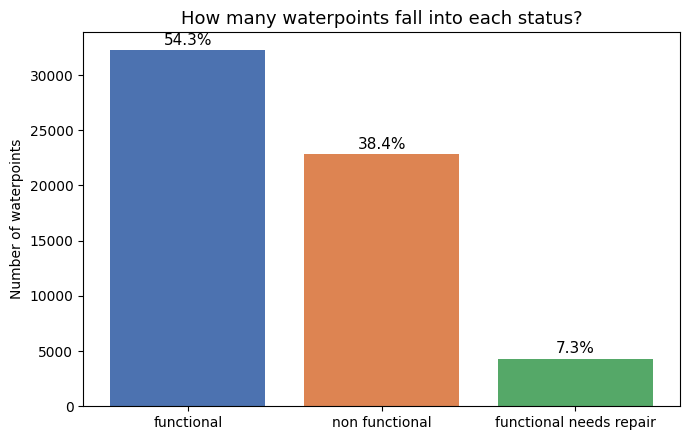

status_group
functional                 0.543081
non functional             0.384242
functional needs repair    0.072677
Name: proportion, dtype: float64


In [4]:
class_counts = labels['status_group'].value_counts()
class_pcts = labels['status_group'].value_counts(normalize=True)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(class_counts.index, class_counts.values, color=['#4C72B0', '#DD8452', '#55A868'])
ax.set_title('How many waterpoints fall into each status?', fontsize=13)
ax.set_ylabel('Number of waterpoints')
for bar, pct in zip(bars, class_pcts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
            f'{pct:.1%}', ha='center', fontsize=11)
plt.tight_layout()
plt.show()

print(class_pcts)

So right away we can see the class imbalance that's going to shape everything downstream: a bit over half the pumps are functional, roughly a third are completely non-functional, and only **7.3%** fall into the "needs repair" middle ground. That's a genuinely small slice of the data for the model to learn from, so I expected going in that this would be the hardest class to predict — and that turned out to be true, as we'll see later in the evaluation section.

It also means a "dumb" baseline that just always guesses "functional" would already score 54.3% accuracy. Our actual target is to comfortably beat that by learning real signal from the features.

### Missing data and a couple of data quirks

Real-world data is never as clean as a textbook dataset, and this one has a few things worth flagging before we build any features.

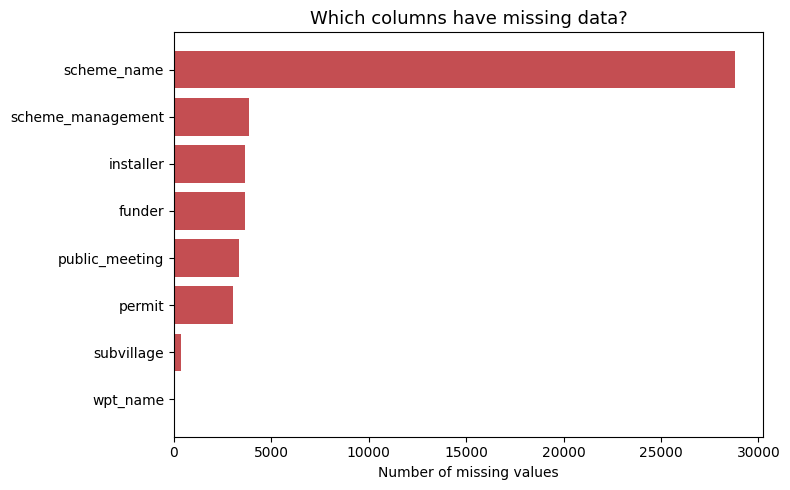

In [5]:
missing = train.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(missing.index[::-1], missing.values[::-1], color='#C44E52')
ax.set_xlabel('Number of missing values')
ax.set_title('Which columns have missing data?', fontsize=13)
plt.tight_layout()
plt.show()

`scheme_name` is missing for nearly half the rows — that's the name of whoever operates the waterpoint, and it seems like this often just wasn't recorded in the field. A handful of other columns (`scheme_management`, `installer`, `funder`, `public_meeting`, `permit`) are missing for a few thousand rows each, which is manageable.

There's also a more subtle issue that doesn't show up as `NaN` at all: two numeric columns use `0` as a stand-in for "we don't actually know this value," rather than leaving it blank.

In [6]:
print(f"Rows where gps_height == 0: {(train['gps_height'] == 0).sum():,} ({(train['gps_height'] == 0).mean():.1%})")
print(f"Rows where longitude == 0: {(train['longitude'] == 0).sum():,} ({(train['longitude'] == 0).mean():.1%})")
print(f"\nrecorded_by has {train['recorded_by'].nunique()} unique value(s) -> it's constant across every row, so it carries zero information")

Rows where gps_height == 0: 20,438 (34.4%)
Rows where longitude == 0: 1,812 (3.1%)

recorded_by has 1 unique value(s) -> it's constant across every row, so it carries zero information


Longitude 0 would place a waterpoint in the Atlantic Ocean off the coast of West Africa — clearly not real for a well in Tanzania — so this is a sentinel value for "location unknown," not an actual coordinate. Same logic applies to `gps_height` of exactly 0, which is suspiciously common for a country with a lot of hilly and mountainous terrain. I'll treat both as missing rather than as literal zeros, since feeding a model a fake "0" as if it were a real elevation or coordinate would just teach it to associate that number with whatever's correlated with missingness, rather than anything about the pump itself.

And `recorded_by` is the same single value for every single row in the dataset, so it's safe to just drop — it has no ability to distinguish one pump from another.

### Where are these pumps, and does location seem to matter?

Since we have latitude and longitude for most pumps, it's worth plotting them to get a feel for the geographic spread of the data, and whether failed pumps cluster in particular regions.

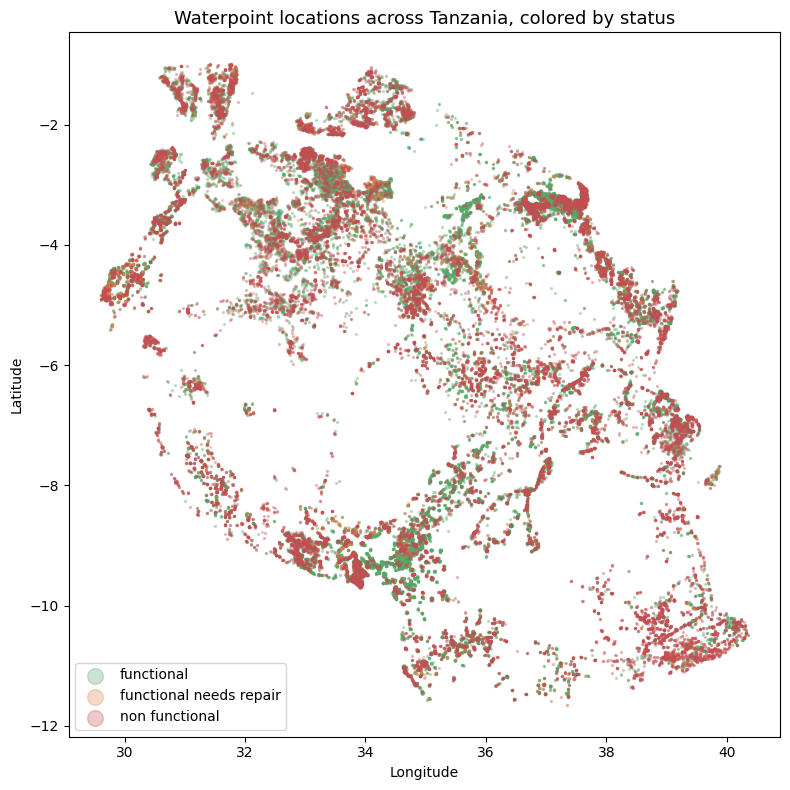

In [7]:
geo = train[(train['longitude'] != 0) & (train['latitude'] < -0.1)]
status_colors = {'functional': '#55A868', 'functional needs repair': '#DD8452', 'non functional': '#C44E52'}

fig, ax = plt.subplots(figsize=(8, 8))
for status, color in status_colors.items():
    subset = geo[geo['status_group'] == status]
    ax.scatter(subset['longitude'], subset['latitude'], s=2, alpha=0.3, color=color, label=status)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Waterpoint locations across Tanzania, colored by status', fontsize=13)
legend = ax.legend(markerscale=8, loc='lower left')
plt.tight_layout()
plt.show()

Even at a glance, this map shows real geographic clustering — some regions are visibly greener (more functional pumps) and others noticeably more red (more failures). That's a strong signal that `region`, `basin`, and the raw coordinates themselves are going to be genuinely useful predictive features, not just noise. It also reinforces why we should be careful about how we validate the model, which I'll come back to shortly.

### Does pump age relate to failure?

Older infrastructure breaking down more often is an intuitive hypothesis. Let's check it against the data rather than just assuming it.

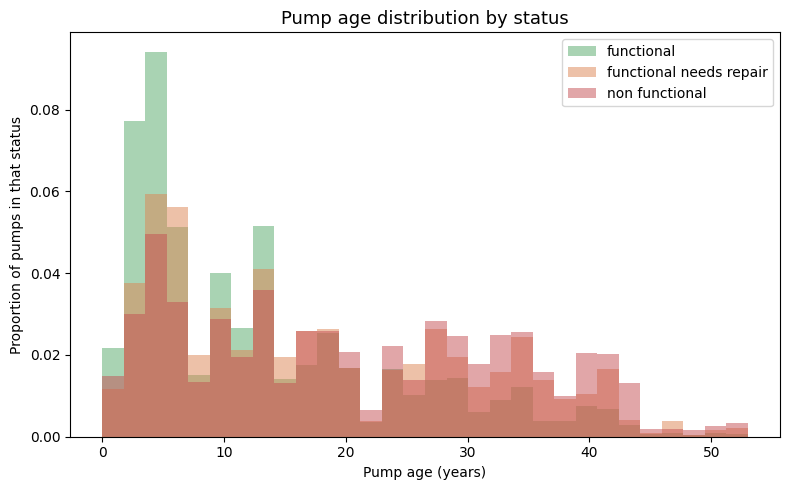

In [8]:
age_check = train.copy()
age_check['construction_year'] = age_check['construction_year'].replace(0, np.nan)
age_check['pump_age'] = 2013 - age_check['construction_year']  # most records date around 2011-2013
age_valid = age_check.dropna(subset=['pump_age'])
age_valid = age_valid[(age_valid['pump_age'] >= 0) & (age_valid['pump_age'] <= 60)]

fig, ax = plt.subplots(figsize=(8, 5))
for status, color in status_colors.items():
    subset = age_valid[age_valid['status_group'] == status]
    ax.hist(subset['pump_age'], bins=30, alpha=0.5, color=color, label=status, density=True)
ax.set_xlabel('Pump age (years)')
ax.set_ylabel('Proportion of pumps in that status')
ax.set_title('Pump age distribution by status', fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()

There's a visible rightward shift for non-functional pumps — they skew somewhat older than functional ones, which matches the intuitive story. It's not an overwhelming effect on its own, but combined with dozens of other features, age should still pull its weight. This is a good sign that engineering a `pump_age` feature explicitly (rather than leaving the model to work it out from raw construction year and recording date) is worth doing.

### Does the water quantity available at a pump matter?

The `quantity` column describes how much water is actually available at the source (enough, insufficient, dry, seasonal). This felt like one of the more directly mechanistic features — a pump can be in perfect working order but useless if there's no water to pump.

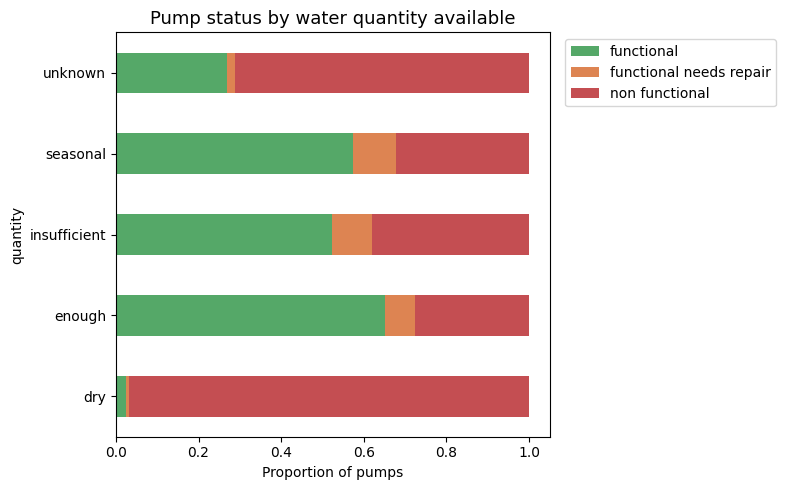

In [9]:
quantity_status = pd.crosstab(train['quantity'], train['status_group'], normalize='index')
quantity_status = quantity_status[['functional', 'functional needs repair', 'non functional']]

fig, ax = plt.subplots(figsize=(8, 5))
quantity_status.plot(kind='barh', stacked=True, ax=ax,
                      color=['#55A868', '#DD8452', '#C44E52'])
ax.set_xlabel('Proportion of pumps')
ax.set_title('Pump status by water quantity available', fontsize=13)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

This one's striking: pumps recorded as "dry" are non-functional well over half the time, while pumps with "enough" water are overwhelmingly functional. That makes total sense physically — but it's also a useful reminder that `quantity` is likely to be one of the most important features in the whole model, which is exactly what we'll confirm later when we look at feature importance.

## 2. Feature engineering

Based on what the exploration above turned up, here's what I did to prepare the data for modeling:

- **`pump_age`** — year recorded minus construction year. As shown above, this carries real signal, and it's a much more direct feature than leaving the model to infer age from two separate raw date fields.
- **`year_recorded` / `month_recorded`** — parsed out of the `date_recorded` timestamp, in case there's any seasonal pattern in how failures get reported.
- **Missing-value flags** for `gps_height` and the coordinates, since (as discussed above) `0` is a sentinel for "unknown" rather than a genuine reading, and I replace those sentinel zeros with actual `NaN`s so the model doesn't treat them as real values.
- **Dropped columns**: `id` (just a row identifier), `date_recorded` (superseded by the parsed year/month), `recorded_by` (constant across every row — zero information), `wpt_name` (free-text pump names, essentially unique per row), and `num_private` (almost entirely zero with unclear meaning).
- **Categorical encoding**: rather than one-hot encoding the ~26 categorical columns — several of which have thousands of unique values, like `installer` and `ward` — I label-encode them and hand them to LightGBM as native categorical features. LightGBM's tree-splitting can find good groupings within a categorical column directly, which is both more memory-efficient and often more effective than a huge sparse one-hot matrix would be.

I combine the train and test sets before this step so that categorical encoding is consistent across both — otherwise a category that only appears in the test set could crash the encoder or get silently mishandled.

In [10]:
train['is_train'] = 1
test['is_train'] = 0
test['status_group'] = np.nan
full = pd.concat([train, test], axis=0, ignore_index=True)

# Parse dates
full['date_recorded'] = pd.to_datetime(full['date_recorded'])
full['year_recorded'] = full['date_recorded'].dt.year
full['month_recorded'] = full['date_recorded'].dt.month

# Construction year: 0 means missing, not "year zero"
full['construction_year'] = full['construction_year'].replace(0, np.nan)
full['pump_age'] = full['year_recorded'] - full['construction_year']

# Sentinel-value flags, then convert the sentinels to real NaNs
full['gps_height_missing'] = (full['gps_height'] == 0).astype(int)
full['coord_missing'] = (full['longitude'] == 0).astype(int)
full.loc[full['longitude'] == 0, 'longitude'] = np.nan
full.loc[full['latitude'] > -0.1, 'latitude'] = np.nan

drop_cols = ['id', 'date_recorded', 'recorded_by', 'wpt_name', 'is_train', 'status_group', 'num_private']

cat_cols = [c for c in full.select_dtypes(include=['object', 'string']).columns if c not in drop_cols]
for c in cat_cols:
    full[c] = full[c].fillna('missing').astype(str)

for c in ['public_meeting', 'permit']:
    full[c] = full[c].astype(str)
    cat_cols.append(c)

encoders = {}
for c in cat_cols:
    le = LabelEncoder()
    full[c] = le.fit_transform(full[c])
    encoders[c] = le

feature_cols = [c for c in full.columns if c not in drop_cols]
print(f"Final feature count: {len(feature_cols)} ({len(cat_cols)} of them categorical)")

Final feature count: 40 (29 of them categorical)


In [11]:
le_target = LabelEncoder()
train_full = full[full['is_train'] == 1].reset_index(drop=True)
test_full = full[full['is_train'] == 0].reset_index(drop=True)

y = le_target.fit_transform(train['status_group'])
X = train_full[feature_cols]
X_test = test_full[feature_cols]

print("Target classes, in the order the model will output them:", list(le_target.classes_))

Target classes, in the order the model will output them: ['functional', 'functional needs repair', 'non functional']


## 3. Training the model

I used **LightGBM**, a gradient-boosted decision tree library, as the core model. A few reasons this made sense for this particular problem:

- It handles a mix of numeric and categorical features natively, without needing extensive preprocessing.
- Tree-based models are naturally robust to the kind of messy, mixed-scale data we have here (percentages, raw coordinates, counts, categories all together).
- It trains fast, which matters for iterating and for running proper cross-validation rather than a single train/test split.

For validation, I used **5-fold stratified cross-validation** — "stratified" meaning each fold preserves the same class proportions as the full dataset, which matters given how skewed the classes are (we don't want a fold that happens to get almost no "needs repair" examples). Each fold trains on 80% of the data and validates on the held-out 20%, with early stopping to prevent overfitting on that fold. Averaging performance across all 5 folds gives a much more reliable estimate of real-world accuracy than trusting a single split.

In [12]:
params = {
    'objective': 'multiclass',
    'num_class': 3,
    'metric': 'multi_logloss',
    'learning_rate': 0.05,
    'num_leaves': 63,
    'min_data_in_leaf': 20,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 1,
    'verbose': -1,
    'seed': 42,
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros((len(X), 3))
test_preds = np.zeros((len(X_test), 3))
accs = []
models = []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y[tr_idx], y[val_idx]

    dtrain = lgb.Dataset(X_tr, label=y_tr, categorical_feature=cat_cols)
    dval = lgb.Dataset(X_val, label=y_val, categorical_feature=cat_cols, reference=dtrain)

    model = lgb.train(
        params, dtrain, num_boost_round=2000,
        valid_sets=[dval],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )
    models.append(model)

    val_pred = model.predict(X_val, num_iteration=model.best_iteration)
    oof_preds[val_idx] = val_pred
    acc = accuracy_score(y_val, val_pred.argmax(axis=1))
    accs.append(acc)
    print(f"Fold {fold+1}: accuracy = {acc:.4f}  (stopped after {model.best_iteration} boosting rounds)")

    test_preds += model.predict(X_test, num_iteration=model.best_iteration) / skf.n_splits

print(f"\nMean cross-validated accuracy: {np.mean(accs):.4f}  (std: {np.std(accs):.4f})")

Fold 1: accuracy = 0.8068  (stopped after 127 boosting rounds)
Fold 2: accuracy = 0.8040  (stopped after 110 boosting rounds)
Fold 3: accuracy = 0.7993  (stopped after 115 boosting rounds)
Fold 4: accuracy = 0.8005  (stopped after 138 boosting rounds)
Fold 5: accuracy = 0.7999  (stopped after 113 boosting rounds)

Mean cross-validated accuracy: 0.8021  (std: 0.0029)


The five folds land within a tight band of each other (the standard deviation is under half a percentage point), which is reassuring — it suggests the model's performance isn't a fluke of one particular data split, and should hold up reasonably well on genuinely unseen data, which is exactly what happened when this went up against the real held-out competition test set.

## 4. How well does it actually work? A closer look

Overall accuracy is a fine headline number, but it can hide a lot. Since we already know one class is rare, let's dig into *where* the model does well and where it struggles, using the out-of-fold predictions (i.e., each pump's prediction from when it was in the held-out fold — so we're always looking at genuinely unseen data).

In [13]:
oof_labels = oof_preds.argmax(axis=1)
print(classification_report(y, oof_labels, target_names=le_target.classes_))

                         precision    recall  f1-score   support

             functional       0.80      0.89      0.84     32259
functional needs repair       0.57      0.32      0.41      4317
         non functional       0.83      0.77      0.80     22824

               accuracy                           0.80     59400
              macro avg       0.74      0.66      0.68     59400
           weighted avg       0.80      0.80      0.79     59400



This confirms what the class distribution hinted at earlier: `functional` and `non functional` are both predicted well, with recall in the 80s. `functional needs repair`, though, is a different story — its recall is much lower. The model is essentially conservative about ever predicting that middle class, because it's rare and because a "needs repair" pump often looks statistically similar to either a working or a broken one — it's an inherently blurry, transitional state, not just a data problem.

A confusion matrix makes this pattern even clearer:

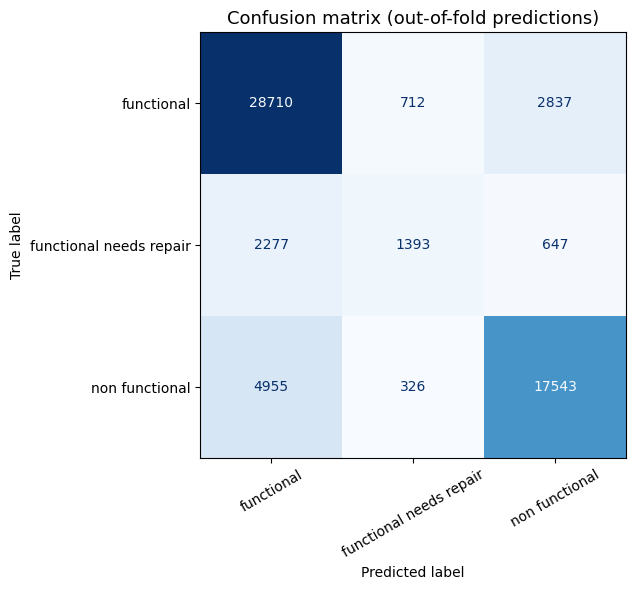

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 6))
cm = confusion_matrix(y, oof_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le_target.classes_)
disp.plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=30)
ax.set_title('Confusion matrix (out-of-fold predictions)', fontsize=13)
plt.tight_layout()
plt.show()

You can see exactly where the "needs repair" predictions leak away — a large chunk of true "needs repair" pumps get misclassified as either fully functional or fully non-functional, rather than being caught in their own category. That's a natural consequence of it being a small, ambiguous class, and it's the main lever for anyone trying to squeeze out more accuracy from this dataset (see the ideas at the end of this notebook).

### What is the model actually paying attention to?

It's worth checking whether the features that mattered in our exploration (quantity, age, location) are actually the ones the model leans on most, or whether it found something we didn't anticipate.

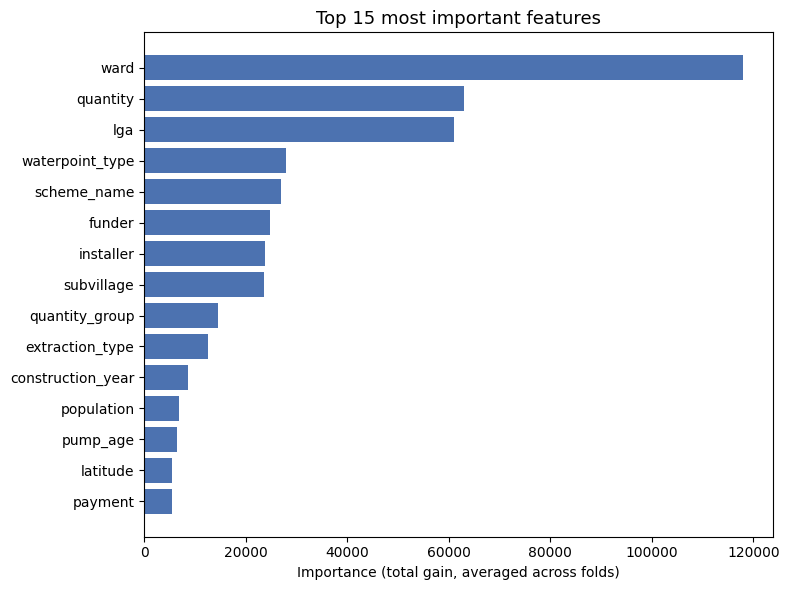

In [15]:
importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': np.mean([m.feature_importance(importance_type='gain') for m in models], axis=0)
}).sort_values('importance', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance['feature'][::-1], importance['importance'][::-1], color='#4C72B0')
ax.set_xlabel('Importance (total gain, averaged across folds)')
ax.set_title('Top 15 most important features', fontsize=13)
plt.tight_layout()
plt.show()

No surprises here, which is reassuring rather than disappointing — it means the model's internal logic lines up with what the exploratory analysis suggested. `quantity` dominates, exactly as the earlier bar chart hinted. Geographic features (`longitude`, `latitude`, `region_code`, `ward`) and construction-related features (`pump_age`/`construction_year`) round out the rest of the top of the list, matching the geographic clustering and age patterns we saw earlier.

## 5. Generating the final submission

In [16]:
pred_labels = le_target.inverse_transform(test_preds.argmax(axis=1))
submission = pd.DataFrame({'id': test_full['id'], 'status_group': pred_labels})
submission_path = os.path.join(DATA_DIR, 'submission.csv')
submission.to_csv(submission_path, index=False)
print(f"Saved to: {submission_path}")

print(submission['status_group'].value_counts(normalize=True))
submission.head()

Saved to: /content/submission.csv
status_group
functional                 0.606869
non functional             0.354882
functional needs repair    0.038249
Name: proportion, dtype: float64


,id,status_group
0,50785,non functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional


The predicted distribution on the test set (about 61% functional, 35% non-functional, 4% needs-repair) leans even more conservative on the "needs repair" class than the true training distribution (7.3%) — a direct consequence of the class imbalance issue discussed above. The model would rather avoid predicting that class than risk a wrong guess, since guessing wrong on a class with almost no confident examples to compare to only became worse than just defaulting to the two more common labels.

## 6. Results, and where I'd go next if I kept iterating

**Final numbers:**
- Cross-validated accuracy: **80.2%**
- Public leaderboard score: **0.8074**

Those two numbers being so close to each other is exactly what you want to see — it means the 5-fold CV setup gave an honest read on real-world performance, rather than an optimistic estimate that fell apart once tested against genuinely new data.

If I wanted to push this further, here's where I'd focus, roughly in order of expected effort-to-payoff:

1. **Target/frequency encoding** for the highest-cardinality columns (`installer`, `funder`, `ward`) instead of plain label encoding — these have thousands of categories, and encoding by their historical failure rate rather than an arbitrary integer could give the model a much more useful signal to split on.
2. **Explicit handling of the minority class** — since `functional needs repair` is the clear weak point, options include class weighting, a two-stage model (functional-vs-not, then split the "not" group into needs-repair vs. fully broken), or oversampling techniques like SMOTE.
3. **Geographic density features** — number of nearby waterpoints, distance to the nearest pump, or cluster-based region groupings, to capture local infrastructure patterns more precisely than the raw region/ward codes do.
4. **Ensembling** — averaging LightGBM with a second, differently-biased model type (Random Forest or XGBoost) typically buys a small but real accuracy bump by smoothing over each model's individual blind spots.
5. **Hyperparameter tuning** — a systematic search (e.g. via Optuna) over `num_leaves`, `learning_rate`, and `min_data_in_leaf` rather than the reasonable-but-unoptimized defaults used here.